# lwh.bdf 原始 EEG 数据探索与交互可视化

针对 **2026-10-22 lwh** 记录：文件头 → 通道 → 波形 → 事件 → 质量 → 频谱/时频 → 切块 → LaBraM 输入。

在 VS Code 中选择 **Python (EEGPT)** 内核，然后依次运行。每幅图的绘图代码均在下方，可直接修改；Plotly 图支持缩放、悬停和图例开关，widgets 支持参数选择。重新打开下载的 Notebook 时，可能需要先信任文件并重新运行，才能启用交互。

**解释边界**：`uV/mm` 的实际数值单位已由采集方确认是 µV；本分析沿用采集参考，不自动去伪迹或改变参考。事件数字编码尚无语义字典，不能把事件间空白当成静息态。默认质量/频谱结果是明确标注时间范围的抽样描述，不是全记录合格证明。只读原始文件，默认不导出数据、不运行训练。


### 控件渲染报错时

如果出现 `Could not render content for application/vnd.jupyter.widget-view+json`，这是控件输出的前端渲染错误；不能据此判断 EEG 读取失败。文件中的旧控件视图已清除，普通 Plotly/Matplotlib 图保留。

1. 重新打开此 Notebook，选择 **Python (EEGPT)**，重启内核并从上到下运行，创建当前会话的控件。已经保存的图可以浏览，但 Python 回调式控件需要运行中的内核。
2. 如果新运行的控件仍报错，执行 VS Code 命令 **Developer: Reload Window**，检查 **Jupyter** 和 **Jupyter Notebook Renderers** 扩展是否启用；这一步涉及本地 VS Code 状态，服务器端执行测试无法代替验证。
3. 为继续分析，可在第一个代码单元设 `ENABLE_IPYWIDGETS = False`，清除原来的控件输出后重新运行。各绘图单元底部提供 `WAVEFORM_PARAMS`、`TIME_FREQUENCY_PARAMS`、`CHUNK_ID`、`EPOCH_PARAMS`，修改参数并重跑即可。Plotly 的缩放、悬停、图例开关仍可使用，但此模式不显示 Python 滑块/按钮。

[VS Code 官方控件排查说明](https://github.com/microsoft/vscode-jupyter/wiki/IPyWidget-Support-in-VS-Code-Python) 也列出控件脚本来源的检查方法；是否受脚本下载影响需结合本地 Jupyter 输出日志判断。


In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt
from scipy import signal
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
# True: 运行当前内核中的控件；False: 只用下方参数字典和 Plotly 图。
ENABLE_IPYWIDGETS = True
widgets = None
if ENABLE_IPYWIDGETS:
    try:
        import ipywidgets as widgets
    except ImportError:
        ENABLE_IPYWIDGETS = False
        print('ipywidgets 未安装：使用参数字典绘图模式。')
from IPython.display import display

# 可在项目根目录或 notebooks 目录启动。
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'preprocess_lwh_labram.py').exists()), None)
if PROJECT is None:
    PROJECT = Path('/home/zhangyn/personalized_FM')
sys.path.insert(0, str(PROJECT))
from preprocess_lwh_labram import read_bdf_header, select_eeg, calibration_factors, POSITION

BDF_PATH = Path('/home/zhangyn/rustfs/oi-data/EMOVID_RAW/20261022161317_20261022_lwh/20261022161317_20261022_lwh/lwh/lwh.bdf')
SOURCE_UNIT = 'uV'   # 仅因为本记录已确认真实物理单位；其他文件需重新确认。
PSD_SEGMENT_SECONDS = 60
PSD_SEGMENT_COUNT = 5
FULL_QUALITY_SCAN = False  # True 会顺序读取整个文件，远程挂载会产生网络流量。
EXPORT_TABLES = False
PROCESSED_PATH = Path('/home/zhangyn/rustfs/personalized-fm/processed/lwh_labram.hdf5')
pio.renderers.default = 'plotly_mimetype+notebook'  # 内嵌 JS，不依赖 CDN。
print('Python:', sys.executable, '| MNE:', mne.__version__)
assert BDF_PATH.is_file(), f'检查 RustFS 挂载及路径：{BDF_PATH}'


Python: /home/zhangyn/miniconda3/envs/EEGPT/bin/python | MNE: 1.4.2


## 1. 文件结构与通道表

BDF 文件头给出采样率、记录时长、物理/数字范围和通道标签。`BDF Annotations` 是事件存储通道，不是脑电信号。时间以记录起点为 0；文件头没有可靠时区信息，不把它擅自转换成 UTC。


In [2]:
header = read_bdf_header(BDF_PATH)
channels = pd.DataFrame(header['channels'])
channels['sample_rate_hz'] = channels['samples_per_record'].astype(int) / header['record_seconds']
eeg_names = [c['label'] for c in select_eeg(header)]  # LaBraM 词表顺序

def classify(name):
    if 'Annotations' in name: return 'annotation'
    if name in eeg_names: return 'EEG'
    if name.upper().startswith(('HEO', 'VEO', 'EOG')): return 'EOG'
    if name.upper() == 'ECG': return 'ECG'
    return 'other'

channels['kind'] = channels['label'].map(classify)
channels['labram_position'] = channels['label'].map(lambda n: POSITION.get(n.upper(), -1) + 1)
summary = pd.Series({
    'file': str(BDF_PATH), 'size_MiB': round(BDF_PATH.stat().st_size/2**20, 2),
    'header_start_without_timezone': header['start_as_stored'],
    'duration_seconds': header['duration_seconds'],
    'duration_minutes': header['duration_seconds']/60,
    'header_channels_including_annotation': len(channels),
    'EEG_channels': len(eeg_names), 'unit_override': SOURCE_UNIT,
})
display(summary.to_frame('value'))
display(channels[['label','kind','unit','sample_rate_hz','physical_min','physical_max',
                  'digital_min','digital_max','transducer','prefilter','labram_position']])


,value
file,/home/zhangyn/rustfs/oi-data/EMOVID_RAW/202610...
size_MiB,950.17
header_start_without_timezone,22.10.26 16.13.19
duration_seconds,5181.0
duration_minutes,86.35
header_channels_including_annotation,65
EEG_channels,59
unit_override,uV


,label,kind,unit,sample_rate_hz,physical_min,physical_max,digital_min,digital_max,transducer,prefilter,labram_position
0,Fpz,EEG,uV/mm,1000.0,-375000,375000,-8388608,8388607,EEG,"HP: DC, LP: 1000 Hz",2
1,Fp1,EEG,uV/mm,1000.0,-375000,375000,-8388608,8388607,EEG,"HP: DC, LP: 1000 Hz",1
2,Fp2,EEG,uV/mm,1000.0,-375000,375000,-8388608,8388607,EEG,"HP: DC, LP: 1000 Hz",3
3,AF3,EEG,uV/mm,1000.0,-375000,375000,-8388608,8388607,EEG,"HP: DC, LP: 1000 Hz",7
4,AF4,EEG,uV/mm,1000.0,-375000,375000,-8388608,8388607,EEG,"HP: DC, LP: 1000 Hz",11
...,...,...,...,...,...,...,...,...,...,...,...
60,HEOR,EOG,uV/mm,1000.0,-375000,375000,-8388608,8388607,EOG,"HP: DC, LP: 1000 Hz",0
61,HEOL,EOG,uV/mm,1000.0,-375000,375000,-8388608,8388607,EOG,"HP: DC, LP: 1000 Hz",0
62,VEOU,EOG,uV/mm,1000.0,-375000,375000,-8388608,8388607,EOG,"HP: DC, LP: 1000 Hz",0
63,VEOL,EOG,uV/mm,1000.0,-375000,375000,-8388608,8388607,EOG,"HP: DC, LP: 1000 Hz",0


## 2. 惰性打开与单位校准

`preload=False` 避免一次载入全部波形，但 MNE 在打开时仍可能扫描远程 BDF 来解析注释。下面的读取函数只返回所需片段，统一为 µV；它复用预处理脚本的单位校正逻辑，避免 `uV/mm` 被 MNE 当作伏后出现百万倍错误。ECG/EOG 也按本文件已确认的物理单位显示，分析对象仍以 EEG 为主。


In [3]:
raw = mne.io.read_raw_bdf(str(BDF_PATH), preload=False, stim_channel=None, verbose='ERROR')
fs = float(raw.info['sfreq'])
n_samples = int(raw.n_times)
duration = n_samples / fs
signal_headers = [c for c in header['channels'] if c['label'] in raw.ch_names]
correction_to_volts = calibration_factors(signal_headers, SOURCE_UNIT)
raw.set_channel_types({n: classify(n).lower() if classify(n) in ('EEG','EOG','ECG') else 'misc'
                       for n in raw.ch_names}, verbose='ERROR')
assert all(float(c['samples_per_record']) / header['record_seconds'] == fs for c in signal_headers)

def read_samples_uv(names, start, stop):
    """0-based, half-open [start, stop); preserve acquisition reference."""
    if not (0 <= start < stop <= n_samples):
        raise ValueError(f'Invalid sample interval [{start}, {stop})')
    values = raw.get_data(picks=list(names), start=int(start), stop=int(stop))
    scale = np.array([correction_to_volts[n] * 1e6 for n in names])
    return values * scale[:, None]

def read_uv(names, start_s, length_s):
    start = int(round(start_s * fs))
    stop = min(n_samples, start + int(round(length_s * fs)))
    return read_samples_uv(names, start, stop), np.arange(start, stop) / fs

print(f'{len(raw.ch_names)} signals | {fs:g} Hz | {duration:g} seconds | no preload')


64 signals | 1000 Hz | 5181 seconds | no preload


## 3. 电极位置图

使用标准 10–20 模板匹配标签，**不是本次受试者实测三维坐标**。辅助通道不放到头皮位置；图上没有的通道不会凭空补造。


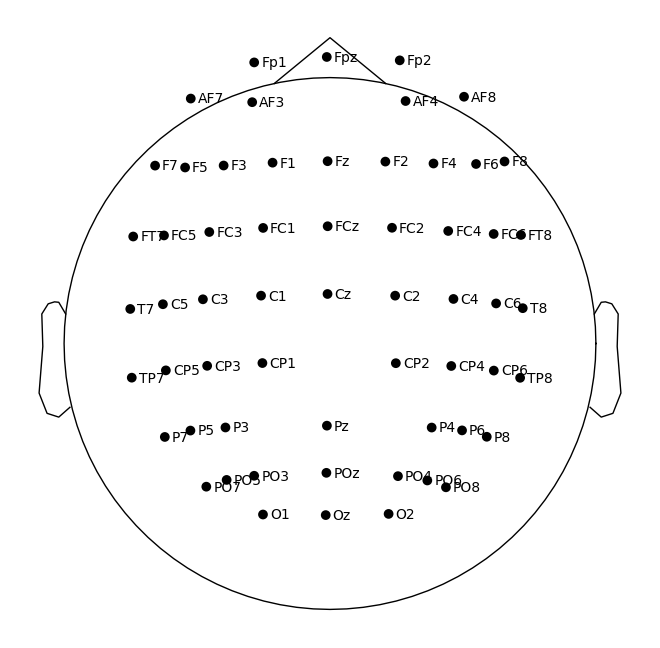

In [4]:
montage = mne.channels.make_standard_montage('standard_1020')
sensor_info = mne.create_info(eeg_names, fs, ch_types='eeg')
sensor_info.set_montage(montage, match_case=False, on_missing='raise')
mne.viz.plot_sensors(sensor_info, kind='topomap', show_names=True, show=False)
plt.show()


## 4. 事件表与时间线

保留原始编码、原始秒时间、原始采样点、四舍五入到 200 Hz 的位置及量化误差。所有索引从 0 开始。`duration=0` 是瞬时标记，不能由此得到刺激持续时间。

将确认过的编码填入 `EVENT_LABELS`；默认显示 `未解释`，没有猜测 `101` 等编码的含义。


In [5]:
EVENT_LABELS = {}  # 例：确认之后填写 {'某编码': '静息开始'}，不要直接照猜。
events = pd.DataFrame({
    'onset_s': raw.annotations.onset - raw.first_time,
    'duration_s': raw.annotations.duration,
    'code': raw.annotations.description.astype(str),
}).sort_values('onset_s', kind='stable').reset_index(drop=True)
events.insert(0, 'event_id', np.arange(len(events)))
events['sample_1000hz'] = np.rint(events.onset_s * fs).astype('int64')  # 本记录 fs=1000
events['sample_200hz'] = np.rint(events.onset_s * 200).astype('int64')
events['rounding_error_ms_200hz'] = (events.sample_200hz/200 - events.onset_s)*1000
events['label'] = events.code.map(EVENT_LABELS).fillna('未解释')
events['gap_from_previous_s'] = events.onset_s.diff()
event_counts = events.groupby('code', sort=True).agg(count=('code','size'), first_s=('onset_s','min'), last_s=('onset_s','max'))
print(f'{len(events)} events, {len(event_counts)} codes; nonzero durations: {(events.duration_s != 0).sum()}')
display(event_counts)
display(events.head(20))
fig = px.scatter(events, x='onset_s', y='code', color='code',
                 hover_data=['event_id','label','duration_s','sample_200hz'],
                 title='All original event markers (seconds from recording start)')
fig.update_yaxes(type='category'); fig.update_xaxes(rangeslider_visible=True)
fig.show()
px.bar(event_counts.reset_index(), x='code', y='count', title='Event counts by original code').update_xaxes(type='category').show()


1347 events, 21 codes; nonzero durations: 0


,count,first_s,last_s
code,,,
101,3,606.780,1492.239
102,3,738.701,5089.945
130,139,606.824,5081.144
131,139,608.614,5085.799
132,101,608.643,5062.154
133,101,626.891,5077.321
140,139,606.814,5081.133
141,137,629.341,5088.217
150,38,903.976,5085.837


,event_id,onset_s,duration_s,code,sample_1000hz,sample_200hz,rounding_error_ms_200hz,label,gap_from_previous_s
0,0,101.279,0.0,250,101279,20256,1.0,未解释,NaN
1,1,101.667,0.0,251,101667,20333,-2.0,未解释,0.388
2,2,102.042,0.0,252,102042,20408,-2.0,未解释,0.375
3,3,391.980,0.0,250,391980,78396,0.0,未解释,289.938
4,4,392.336,0.0,251,392336,78467,-1.0,未解释,0.356
5,5,392.777,0.0,252,392777,78555,-2.0,未解释,0.441
6,6,597.508,0.0,250,597508,119502,2.0,未解释,204.731
7,7,598.083,0.0,251,598083,119617,2.0,未解释,0.575
8,8,598.462,0.0,252,598462,119692,-2.0,未解释,0.379
9,9,606.780,0.0,101,606780,121356,0.0,未解释,8.318


## 5. 交互波形浏览器：EEG / EOG / ECG + 事件

选择通道和开始时间，点击“绘制”。显示可以减去各通道片段中位数，也可以加 0.5–45 Hz 显示滤波；这些选项**只用于当前图**，不改变原始数据。为限制浏览器负担，绘图采用每个小时间箱的最小值/最大值包络，保留尖峰；精细形态请缩短时间窗。图中通道名括号内是居中前中位数。


In [6]:
def envelope_indices(x, limit=2400):
    if x.size <= limit: return np.arange(x.size)
    width = int(np.ceil(x.size / (limit//2)))
    idx = []
    for a in range(0, x.size, width):
        segment = x[a:a+width]
        idx.extend([a+int(np.argmin(segment)), a+int(np.argmax(segment))])
    return np.unique(idx)

def plot_waveform(start_s=600.0, length_s=10.0, names=('Fp1','Cz','O1'), spacing_uv=150.0,
                  center=True, display_filter=False):
    if not names: return print('请选择至少一个通道。')
    if len(names)>16: return print('为保证可读性，一次最多选择 16 个通道。')
    x, t = read_uv(names, start_s, length_s)
    if display_filter:
        sos = signal.butter(4, [0.5,45], fs=fs, btype='bandpass', output='sos')
        x = signal.sosfiltfilt(sos, x, axis=-1)
    med = np.median(x, axis=1)
    if center: x = x-med[:,None]
    fig = go.Figure()
    offsets = np.arange(len(names))[::-1] * spacing_uv
    for i, name in enumerate(names):
        idx = envelope_indices(x[i])
        fig.add_scatter(x=t[idx], y=x[i,idx]+offsets[i], mode='lines', name=name,
                        customdata=x[i,idx], hovertemplate='%{x:.3f}s / %{customdata:.2f} uV<extra>%{fullData.name}</extra>')
    selected_events = events[(events.onset_s >= t[0]) & (events.onset_s <= t[-1])]
    for row in selected_events.itertuples():
        fig.add_vline(x=row.onset_s, line_width=1, line_dash='dot', line_color='gray',
                      annotation_text=row.code, annotation_position='top')
    fig.update_layout(title=f'Waveform | display filter={display_filter} | centered={center}',
                      height=max(400, 65*len(names)), xaxis_title='Seconds from recording start',
                      yaxis=dict(tickvals=offsets,ticktext=[f'{n} ({v:.1f} uV)' for n,v in zip(names,med)]),
                      showlegend=False)
    fig.show()

if ENABLE_IPYWIDGETS:
    wave_browser = widgets.interactive(
        plot_waveform, {'manual': True, 'manual_name': '绘制波形'},
        start_s=widgets.FloatSlider(value=600,min=0,max=duration-2,step=.1,description='开始秒'),
        length_s=widgets.FloatSlider(value=10,min=2,max=60,step=1,description='时长秒'),
        names=widgets.SelectMultiple(options=raw.ch_names,value=('Fp1','Cz','O1'),description='通道'),
        spacing_uv=widgets.FloatSlider(value=150,min=10,max=2000,step=10,description='间距 µV'),
        center=True, display_filter=False)
    display(wave_browser)

WAVEFORM_PARAMS = dict(start_s=600., length_s=10., names=('Fp1','Cz','O1'),
                       spacing_uv=150., center=True, display_filter=False)
plot_waveform(**WAVEFORM_PARAMS)


## 6. 抽样/全量质量筛查与功率谱

默认在记录开头、中间、末尾等均匀选 5 个 60 秒片段。检查：均值、标准差、峰峰值、绝对振幅 >200 µV 比例、连续相邻样本几乎相等比例、接近 ADC 上下限比例和非有限值数。**200 µV 是可调筛查阈值，不是医学判定或自动剔除标准**；辅助通道与 EEG 不能使用相同阈值解释。

PSD 使用未滤波、未重参考的 EEG，经每个 Welch 子窗去常数趋势；4 秒 Hann 窗、50% 重叠，单位 µV²/Hz。默认只代表这些抽样片段。将开头 `FULL_QUALITY_SCAN=True` 后重跑本节，可按 60 秒块扫描整个文件（内存有界）；不足 4 秒尾块仍做质量统计，但不进入 PSD。


In [7]:
AMPLITUDE_THRESHOLD_UV = 200.0
if FULL_QUALITY_SCAN:
    scan_ranges = [(a, min(a+int(60*fs), n_samples)) for a in range(0,n_samples,int(60*fs))]
else:
    segment_n = min(n_samples, int(PSD_SEGMENT_SECONDS*fs))
    starts = np.unique(np.linspace(0,n_samples-segment_n,PSD_SEGMENT_COUNT).astype(int))
    scan_ranges = [(int(a),int(a+segment_n)) for a in starts]
scan_intervals = pd.DataFrame([(a/fs,b/fs,(b-a)/fs) for a,b in scan_ranges],
                             columns=['start_s','stop_s','duration_s'])
display(scan_intervals)
print('扫描范围:', '全记录' if FULL_QUALITY_SCAN else '抽样片段', '| seconds:',scan_intervals.duration_s.sum())

quality_rows, spectra, spectrum_weights, spectrum_ranges = [], [], [], []
header_by_name = {c['label']:c for c in signal_headers}
eeg_indices = [raw.ch_names.index(n) for n in eeg_names]
for a,b in scan_ranges:
    x = read_samples_uv(raw.ch_names,a,b)
    for i,n in enumerate(raw.ch_names):
        v = x[i]; finite = v[np.isfinite(v)]
        c = header_by_name[n]
        lo,hi = float(c['physical_min']),float(c['physical_max'])  # 此记录确认为 µV
        lsb = (hi-lo)/(float(c['digital_max'])-float(c['digital_min']))
        quality_rows.append(dict(channel=n,kind=classify(n),start_s=a/fs,stop_s=b/fs,
            n_samples=len(v),nonfinite=int((~np.isfinite(v)).sum()),
            mean_uv=np.mean(finite) if finite.size else np.nan,
            std_uv=np.std(finite) if finite.size else np.nan,
            ptp_uv=np.ptp(finite) if finite.size else np.nan,
            large_fraction=np.mean(np.abs(finite)>AMPLITUDE_THRESHOLD_UV) if finite.size else np.nan,
            near_rail_fraction=np.mean((finite<=lo+lsb)|(finite>=hi-lsb)) if finite.size else np.nan,
            flat_step_fraction=np.mean(np.abs(np.diff(v))<lsb*.1) if len(v)>1 else np.nan))
    eeg = x[eeg_indices]
    if b-a >= int(4*fs) and np.isfinite(eeg).all():
        freqs, psd = signal.welch(eeg, fs=fs, window='hann', nperseg=int(4*fs),
                                 noverlap=int(2*fs), detrend='constant', scaling='density',axis=-1)
        spectra.append(psd)
        spectrum_weights.append(1+(b-a-int(4*fs))//int(2*fs))
        spectrum_ranges.append((a/fs,b/fs))
    del x
quality = pd.DataFrame(quality_rows)
assert spectra, '没有可用于 PSD 的有效片段。'
psd_by_segment = np.stack(spectra)
mean_psd = np.average(psd_by_segment, axis=0, weights=spectrum_weights)
quality_summary = quality.groupby(['channel','kind']).agg(
    max_window_std_uv=('std_uv','max'), max_window_ptp_uv=('ptp_uv','max'),
    max_large_fraction=('large_fraction','max'), max_near_rail_fraction=('near_rail_fraction','max'),
    max_flat_step_fraction=('flat_step_fraction','max'), nonfinite=('nonfinite','sum'))
display(quality_summary.sort_values('max_window_ptp_uv',ascending=False))
qmap = quality[quality.kind=='EEG'].pivot(index='channel',columns='start_s',values='std_uv')
px.imshow(qmap, aspect='auto', labels={'x':'Window start (s)','y':'Channel','color':'SD (uV)'},
          title='Per-window EEG standard deviation (sampled unless full scan enabled)').show()


,start_s,stop_s,duration_s
0,0.00,60.00,60.0
1,1280.25,1340.25,60.0
2,2560.50,2620.50,60.0
3,3840.75,3900.75,60.0
4,5121.00,5181.00,60.0


扫描范围: 抽样片段 | seconds: 300.0


,,max_window_std_uv,max_window_ptp_uv,max_large_fraction,max_near_rail_fraction,max_flat_step_fraction,nonfinite
channel,kind,,,,,,
HEOL,EOG,35948.707060,315293.867308,1.0,0.0,0.000283,0
PO4,EEG,8471.401416,73217.873169,1.0,0.0,0.003750,0
POz,EEG,4356.663943,26518.555076,1.0,0.0,0.006167,0
Fpz,EEG,3032.852001,12454.301861,1.0,0.0,0.008183,0
Fp1,EEG,1493.728903,8347.392580,1.0,0.0,0.007933,0
...,...,...,...,...,...,...,...
CP1,EEG,90.646292,442.206886,1.0,0.0,0.030201,0
HEOR,EOG,0.000000,0.000000,1.0,1.0,1.000000,0
ECG,ECG,0.000000,0.000000,1.0,1.0,1.000000,0


## 7. 频谱、频段分布与工频检查

PSD 的 dB 表示 `10·log10(PSD / 1 µV²/Hz)`。频段取 δ 1–4、θ 4–8、α 8–13、β 13–30、低 γ 30–45 Hz；相对功率分母为这五个相邻频段总功率（1–45 Hz），不含 DC 或 50 Hz 工频。边界用梯形积分，避免把边界频点计成两份完整频率箱。

49–51 Hz 与相邻频带的比值仅提示窄带工频峰，不能单独确定接地问题或信号质量。头皮分布是模板上的插值图，不代表源定位。


,channel,line_to_neighbor_ratio
52,POz,1616.914845
39,CP4,81.719364
46,P4,18.909218
53,PO4,2.756392
12,F2,2.363160
11,Fz,1.457695
54,PO6,1.345814
55,PO8,1.298476
48,P8,1.265954
23,FC6,1.240279


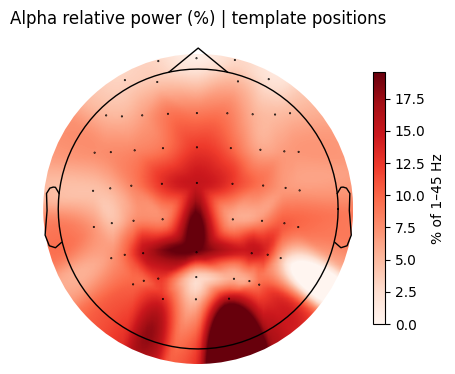

In [8]:
BANDS = {'delta (1-4)':(1,4), 'theta (4-8)':(4,8), 'alpha (8-13)':(8,13),
         'beta (13-30)':(13,30), 'low gamma (30-45)':(30,45)}
def band_integral(psd, low, high):
    idx = (freqs>=low)&(freqs<=high)
    return np.trapz(psd[...,idx],freqs[idx],axis=-1)
band_power = pd.DataFrame({name:band_integral(mean_psd,*bounds) for name,bounds in BANDS.items()},index=eeg_names)
relative_power = band_power.div(band_power.sum(axis=1).replace(0,np.nan),axis=0)*100
line_density = band_integral(mean_psd,49,51)/2
neighbor_density = (band_integral(mean_psd,45,48)+band_integral(mean_psd,52,55))/6
line_ratio = pd.DataFrame({'channel':eeg_names,'line_to_neighbor_ratio':line_density/np.maximum(neighbor_density,1e-30)})
display(line_ratio.sort_values('line_to_neighbor_ratio',ascending=False).head(10))

use = (freqs>=.5)&(freqs<=100)
fig = go.Figure()
for n in ['Fp1','Cz','O1','O2']:
    i=eeg_names.index(n)
    fig.add_scatter(x=freqs[use], y=10*np.log10(np.maximum(mean_psd[i,use],1e-30)),name=n)
fig.add_vline(x=50,line_dash='dash',line_color='red')
fig.update_layout(title='Raw EEG Welch PSD | '+('full recording' if FULL_QUALITY_SCAN else 'sampled windows'),xaxis_title='Frequency (Hz)',yaxis_title='dB re 1 uV²/Hz')
fig.show()
px.imshow(relative_power,aspect='auto',zmin=0,zmax=100,
          labels={'x':'Frequency band','y':'Channel','color':'% of 1–45 Hz'},
          title='Relative band power by channel').show()
fig,ax=plt.subplots(figsize=(5,5))
mne.viz.plot_topomap(relative_power['alpha (8-13)'].values,sensor_info,axes=ax,show=False,
                     vlim=(0, max(1.,relative_power['alpha (8-13)'].max())), contours=0)
ax.set_title('Alpha relative power (%) | template positions')
fig.colorbar(ax.images[0],ax=ax,shrink=.6,label='% of 1–45 Hz')
plt.show()


## 8. 交互时频图

选择单个通道和时间窗，以 2 秒 Hann 窗、0.25 秒步长显示 1–80 Hz PSD，同时叠加该范围内事件。时间和频率分辨率由参数决定；原始信号中眼动、肌电或运动同样会出现在时频图上，不能把颜色直接解释成情绪。


In [9]:
def plot_time_frequency(channel='O1', start_s=600., length_s=60.):
    x,t=read_uv([channel],start_s,length_s)
    f,tt,p=signal.spectrogram(x[0],fs=fs,window='hann',nperseg=int(2*fs),
                             noverlap=int(1.75*fs),detrend='constant',scaling='density',mode='psd')
    take=(f>=1)&(f<=80)
    fig=go.Figure(go.Heatmap(x=tt+t[0],y=f[take],z=10*np.log10(np.maximum(p[take],1e-30)),
                            colorbar_title='dB uV²/Hz',colorscale='Viridis'))
    for row in events[(events.onset_s>=t[0])&(events.onset_s<=t[-1])].itertuples():
        fig.add_vline(x=row.onset_s,line_dash='dot',annotation_text=row.code)
    fig.update_layout(title=f'{channel} raw spectrogram',xaxis_title='Recording time (s)',yaxis_title='Hz')
    fig.show()
if ENABLE_IPYWIDGETS:
    display(widgets.interactive(plot_time_frequency,{'manual':True,'manual_name':'绘制时频图'},
        channel=widgets.Dropdown(options=eeg_names,value='O1'),
        start_s=widgets.FloatSlider(value=600,min=0,max=duration-4,step=1),
        length_s=widgets.FloatSlider(value=60,min=4,max=180,step=1)))
TIME_FREQUENCY_PARAMS = dict(channel='O1', start_s=600., length_s=60.)
plot_time_frequency(**TIME_FREQUENCY_PARAMS)


## 9. 固定长度切块：只建索引，不复制整份数据

默认 **8 秒窗口、8 秒步长**；窗口采用 `[start, stop)`，边界上的事件归入右侧窗口。可设 `stride_s < window_s` 得到重叠窗口。返回原始采样索引、对应时间、事件清单、未覆盖尾段；这里只做索引，不自动生成类别。原始 1000 Hz 的 8 秒窗口是 `(59,8000)`，LaBraM 200 Hz 的 8 秒才是 `(59,1600)`。


In [10]:
def make_windows(window_s=8.,stride_s=8.):
    win,step=int(round(window_s*fs)),int(round(stride_s*fs))
    if win<=0 or step<=0 or win>n_samples: raise ValueError('无效窗口或步长')
    rows=[]
    for i,a in enumerate(range(0,n_samples-win+1,step)):
        b=a+win
        hits=events[(events.onset_s>=a/fs)&(events.onset_s<b/fs)]
        rows.append(dict(window_id=i,start_sample=a,stop_sample=b,start_s=a/fs,stop_s=b/fs,
                         event_count=len(hits),event_codes=','.join(hits.code),
                         event_ids=','.join(hits.event_id.astype(str)),state='unknown'))
    return pd.DataFrame(rows)
windows=make_windows()
display(windows.head(12))
print(f'{len(windows)} windows | trailing uncovered seconds: {(n_samples-windows.stop_sample.iloc[-1])/fs:g}')
print('若步长大于窗口长度，中间还存在空隙；重叠窗口也不能直接随机分配给训练/测试集。')

def plot_chunk(window_id=75):
    w=windows.iloc[window_id]
    plot_waveform(start_s=float(w.start_s),length_s=float(w.stop_s-w.start_s),names=('Fp1','Cz','O1'))
    display(events[(events.onset_s>=w.start_s)&(events.onset_s<w.stop_s)])
if ENABLE_IPYWIDGETS:
    display(widgets.interactive(plot_chunk,{'manual':True,'manual_name':'查看切块'},
                               window_id=widgets.IntSlider(value=min(75,len(windows)-1),min=0,max=len(windows)-1)))
CHUNK_ID = min(75, len(windows)-1)  # 改为其他窗口编号后重跑本单元。
plot_chunk(CHUNK_ID)


,window_id,start_sample,stop_sample,start_s,stop_s,event_count,event_codes,event_ids,state
0,0,0,8000,0.0,8.0,0,,,unknown
1,1,8000,16000,8.0,16.0,0,,,unknown
2,2,16000,24000,16.0,24.0,0,,,unknown
3,3,24000,32000,24.0,32.0,0,,,unknown
4,4,32000,40000,32.0,40.0,0,,,unknown
5,5,40000,48000,40.0,48.0,0,,,unknown
6,6,48000,56000,48.0,56.0,0,,,unknown
7,7,56000,64000,56.0,64.0,0,,,unknown
8,8,64000,72000,64.0,72.0,0,,,unknown
9,9,72000,80000,72.0,80.0,0,,,unknown


647 windows | trailing uncovered seconds: 5
若步长大于窗口长度，中间还存在空隙；重叠窗口也不能直接随机分配给训练/测试集。


,event_id,onset_s,duration_s,code,sample_1000hz,sample_200hz,rounding_error_ms_200hz,label,gap_from_previous_s
9,9,606.780,0.0,101,606780,121356,0.0,未解释,8.318
10,10,606.814,0.0,140,606814,121363,1.0,未解释,0.034
11,11,606.824,0.0,130,606824,121365,1.0,未解释,0.010


## 10. 事件对齐窗口与单通道叠加

每个事件取 `[-1,+2)` 秒。记录边界不足的事件显式标记，不补零；仅选一个事件码、一个通道、最多 30 次，避免一次读取大量数据。图中的均值只是这些窗口的描述性平均，**不是经过试次条件核验、伪迹剔除的正式 ERP**；默认不做基线校正，也不解释编码含义。


In [11]:
def make_event_windows(code_value, tmin=-1., tmax=2.):
    if tmax<=tmin: raise ValueError('tmax 必须大于 tmin')
    table=events[events.code==str(code_value)].copy()
    anchor=np.rint(table.onset_s*fs).astype('int64')
    table['start_sample']=anchor+int(round(tmin*fs))
    table['stop_sample']=anchor+int(round(tmax*fs))
    table['valid']=(table.start_sample>=0)&(table.stop_sample<=n_samples)
    return table

def plot_event_epochs(code_value='140',channel='Cz',limit=20):
    table=make_event_windows(code_value)
    selected=table[table.valid].head(limit)
    if selected.empty: return print('没有边界完整的事件窗口。')
    epochs=np.stack([read_samples_uv([channel],int(r.start_sample),int(r.stop_sample))[0]
                     for r in selected.itertuples()])
    time=np.arange(epochs.shape[1])/fs-1
    fig=go.Figure()
    # 保留完整 1000 Hz 数据；最多 30 个短窗口。
    for row,y in zip(selected.itertuples(),epochs):
        fig.add_scatter(x=time,y=y,name=f'event {row.event_id}',opacity=.25,line_width=1,showlegend=False)
    fig.add_scatter(x=time,y=epochs.mean(axis=0),name='Selected-window mean',line=dict(color='black',width=3))
    fig.add_vline(x=0,line_dash='dash')
    fig.update_layout(title=f'{channel} | code {code_value} | first {len(selected)} valid events | no baseline correction',
                      xaxis_title='Seconds relative to marker',yaxis_title='uV')
    fig.show()
    print('总事件:',len(table),'边界不足:',int((~table.valid).sum()),'展示:',len(selected))
    display(selected[['event_id','code','onset_s','start_sample','stop_sample']])
if ENABLE_IPYWIDGETS:
    display(widgets.interactive(plot_event_epochs,{'manual':True,'manual_name':'查看事件窗口'},
        code_value=widgets.Dropdown(options=sorted(events.code.unique()),value='140'),
        channel=widgets.Dropdown(options=eeg_names,value='Cz'),limit=widgets.IntSlider(value=20,min=1,max=30)))
EPOCH_PARAMS = dict(code_value='140', channel='Cz', limit=20)
plot_event_epochs(**EPOCH_PARAMS)


总事件: 139 边界不足: 0 展示: 20


,event_id,code,onset_s,start_sample,stop_sample
10,10,140,606.814,605814,608814
20,20,140,631.407,630407,633407
34,34,140,880.905,879905,882905
44,44,140,899.423,898423,901423
52,52,140,920.209,919209,922209
62,62,140,943.253,942253,945253
72,72,140,968.362,967362,970362
82,82,140,1010.972,1009972,1012972
90,90,140,1032.015,1031015,1034015
100,100,140,1066.892,1065892,1068892


## 11. 静息态/任务态区间：等待真实范式映射

只有取得实验代码表后才填写 `STATE_PAIRS`。例如 `{'rest': ('已确认的静息开始码','已确认的静息结束码')}`。下面检查重复开始、孤立结束、未结束、非正时长和区间重叠；有歧义时停止，要求核对范式，不能通过最近邻配对掩盖问题。

窗口完全包含在一个已确认区间中才赋予该状态。跨边界标记 `mixed/boundary`，未覆盖保持 `unknown`。区间间隙不自动视为静息。此方法适合明确成对且互斥的阶段码；嵌套试次/阶段体系需要分别建表。


In [12]:
STATE_PAIRS = {}  # 必须由 EMOVID 范式/采集打标代码确认后填写。

def pair_state_intervals(event_table, pairs):
    codes=[str(c) for pair in pairs.values() for c in pair]
    if len(set(codes))!=len(codes): raise ValueError('不同阶段的起止码不能重复；嵌套层级请单独分析')
    rows=[]
    for state,(begin,end) in pairs.items():
        opened=None
        for r in event_table[event_table.code.isin([str(begin),str(end)])].itertuples():
            if r.code==str(begin):
                if opened is not None: raise ValueError(f'{state}: 重复开始 @ {r.onset_s}')
                opened=r
            else:
                if opened is None: raise ValueError(f'{state}: 孤立结束 @ {r.onset_s}')
                if r.onset_s<=opened.onset_s: raise ValueError('区间时长必须 > 0')
                rows.append(dict(state=state,start_s=opened.onset_s,stop_s=r.onset_s,
                                 start_event_id=opened.event_id,stop_event_id=r.event_id))
                opened=None
        if opened is not None: raise ValueError(f'{state}: 开始标记没有对应结束')
    result=pd.DataFrame(rows,columns=['state','start_s','stop_s','start_event_id','stop_event_id'])
    result=result.sort_values('start_s').reset_index(drop=True)
    if len(result)>1 and np.any(result.start_s.values[1:]<np.maximum.accumulate(result.stop_s.values)[:-1]):
        raise ValueError('存在阶段重叠，请核对起止映射')
    return result

state_intervals=pair_state_intervals(events,STATE_PAIRS)
labeled_windows=windows.copy()
for i,w in labeled_windows.iterrows():
    hits=state_intervals[(state_intervals.start_s<w.stop_s)&(state_intervals.stop_s>w.start_s)]
    complete=hits[(hits.start_s<=w.start_s)&(hits.stop_s>=w.stop_s)]
    labeled_windows.at[i,'state']=complete.state.iloc[0] if len(complete)==1 else ('mixed/boundary' if len(hits) else 'unknown')
if state_intervals.empty:
    print('尚无语义映射；全部固定窗口保持 unknown。')
else:
    display(state_intervals)
    fig=go.Figure()
    for r in state_intervals.itertuples():
        fig.add_scatter(x=[r.start_s,r.stop_s],y=[r.state,r.state],mode='lines',line_width=12,name=r.state)
    fig.update_layout(title='Confirmed phase intervals',xaxis_title='Seconds')
    fig.show()
display(labeled_windows.state.value_counts().to_frame('windows'))


尚无语义映射；全部固定窗口保持 unknown。

,windows
unknown,647


## 12. 可选：已有 LaBraM HDF5 对照与 patch 形状

只读取已有预处理文件的一小段，不在此重复跑预处理。检查来源路径、裁剪偏移、处理状态、通道、单位和事件；用同一原始时间轴比较原始/处理后波形。输出文件为 µV，模型前才除以 100。滤波/重采样的差异是预期现象，不代表逐点相等。


In [13]:
import h5py
if PROCESSED_PATH.exists():
    with h5py.File(PROCESSED_PATH,'r') as f:
        assert f.attrs['processing_status']=='complete'
        meta=json.loads(f.attrs['metadata_json'])
        assert Path(meta['source_path']).resolve()==BDF_PATH.resolve(), '处理文件来自不同原始文件'
        g=f['lwh']; ds=g['eeg']
        names=[v.decode() if isinstance(v,bytes) else str(v) for v in ds.attrs['chOrder']]
        out_fs=float(ds.attrs['rsFreq'])
        assert out_fs==200 and ds.attrs['unit']=='uV'
        crop_start=float(meta['crop_start_seconds'])
        output_start_s=min(600.,max(0.,ds.shape[1]/out_fs-8))
        start=int(round(output_start_s*out_fs)); stop=start+1600
        assert stop<=ds.shape[1], '处理后文件不足 8 秒'
        chunk=ds[:,start:stop]
        model_x=(chunk.astype(np.float32)/100).reshape(1,len(names),8,200)
        assert np.isfinite(model_x).all()
        print('HDF5:',ds.shape,'| model input:',model_x.shape,'| annotations:',len(g['events/description']))
        print('crop start (original seconds):',crop_start)
        absolute_start=crop_start+start/out_fs
        original,t=read_uv(['Cz'],absolute_start,8)
        fig=go.Figure()
        fig.add_scatter(x=t,y=original[0],name='Raw Cz')
        fig.add_scatter(x=absolute_start+np.arange(1600)/out_fs,y=chunk[names.index('CZ')],name='LaBraM Cz')
        fig.update_layout(title='Same interval: raw vs processed',xaxis_title='Original recording seconds',yaxis_title='uV')
        fig.show()
else:
    print('未找到预处理文件，跳过；其他原始数据分析不受影响。')


HDF5: (59, 1036200) | model input: (1, 59, 8, 200) | annotations: 1347
crop start (original seconds): 0.0


## 13. 按需导出分析表（默认关闭）

设 `EXPORT_TABLES=True` 后重跑此单元，会在本地 `analysis/lwh_notebook_exports/时间戳/` 下保存表格和配置；不会覆盖已有目录，也不会修改原始 BDF。波形与全部 EEG 不自动复制。Plotly 图工具栏可导出 PNG；如需独立交互 HTML，对任意图调用 `fig.write_html('自选路径.html', include_plotlyjs=True)`，输出中可能包含原始波形片段，应按数据访问规则存放。

**建模提醒**：先按受试者/会话/实验区段划分数据集，再在各集合内切块；重叠窗口、同一次事件或紧邻片段跨训练/测试会引入泄漏。这里的固定窗口不是情绪标签，采样质量指标也不会自动排除窗口。


In [14]:
if EXPORT_TABLES:
    from datetime import datetime, timezone
    export_dir=PROJECT/'analysis'/'lwh_notebook_exports'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    export_dir.mkdir(parents=True,exist_ok=False)
    for name,table in {'channels':channels,'events':events,'event_counts':event_counts.reset_index(),
                       'scan_intervals':scan_intervals,'quality_windows':quality,
                       'relative_band_power':relative_power.reset_index(names='channel'),
                       'fixed_windows':labeled_windows,'state_intervals':state_intervals}.items():
        table.to_csv(export_dir/f'{name}.csv',index=False)
    config={'source':str(BDF_PATH),'source_size':BDF_PATH.stat().st_size,'unit':SOURCE_UNIT,
            'sampling_hz':fs,'full_quality_scan':FULL_QUALITY_SCAN,'event_labels':EVENT_LABELS,
            'state_pairs':STATE_PAIRS,'amplitude_threshold_uv':AMPLITUDE_THRESHOLD_UV,
            'psd_segment_ranges_seconds':spectrum_ranges,'mne_version':mne.__version__}
    (export_dir/'config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2))
    print(export_dir)
else:
    print('未导出文件；将 EXPORT_TABLES 改为 True 后可保存分析表。')


未导出文件；将 EXPORT_TABLES 改为 True 后可保存分析表。


## 14. 如何评估质量：全记录复核结果

本节加载本次全量检查表：原始 **5181 秒 / 87 个块（最后一块不足 60 秒）**，以及已有 LaBraM 文件中的 **647 个 8 秒窗口**，尾部 5 秒不进入固定窗口统计。前面第 6 节保存的结果仍为默认 300 秒抽样，请区分两者。这里显示的是已生成的审计快照；需要重算时，在 EEGPT 环境运行 `python analysis/lwh_bdf/run_quality_audit.py`。

评估应分三层：**通道是否有有效信号 → 哪些时间段受污染 → 目标任务窗口还能保留多少**。文件能读取、没有 NaN 或模型能前向运行，都不等于信号质量合格。

- **辅助通道**：ECG、HEOR、VEOU、VEOL 全记录恒定在 −375000 µV（文件物理下限），不能作为有效心电/眼电参考；这可能与未接入或通道配置有关，单凭波形不能确定硬件原因。
- **优先检查 EEG**：PO4、POz 存在极端振幅片段；POz 的全记录平均 PSD 在 50 Hz 附近明显突出。CP4/P4 也有相对窄带峰，但要同时看绝对功率，不能只按比值判定整条坏导联。额前通道大幅波动需结合原始形态及可用眼电人工复核，不能仅凭位置认定眨眼。
- **直流偏置陷阱**：第 6 节 `large_fraction` 使用原始 `abs(x)>200 µV`，会受 DC 偏置影响；不要以它直接判定坏数据。下表改看 LaBraM 预处理后的 `max(x)-min(x)`，峰峰值对常数偏置不敏感，但仍会受漂移、窗口长度和伪迹影响。
- **阈值是筛查条件**：200 / 500 / 1000 µV 仅用来比较敏感性，并非统一合格标准。表中“至少一通道超阈值”是待复核，不是已经判定整个窗口不可用；坏导联与局部坏片段应分别处理。
- **阶段要区分**：`ordinary_video` / `emotion_video` 仅表示 8 秒窗完全落在对应起止码之间；跨阶段、评分、会话外空闲等归入 `mixed_or_other`，不表示它们全是坏数据，也不表示视频窗口已通过质量检查。起止配对不证明完整播放或有正确情绪标签。

建议先从下方最严重的窗口打开波形，比较 PO4/POz 与 Cz 等其他通道，同时看事件。确认局部异常后标注时间范围；确认长期异常才标注整条坏导联。清理后重新检查 PSD、振幅和各任务条件的保留时长。不要为匹配模型形状而拼接不连续短休息，也不要把滤波成功视为伪迹已经清除。

方法依据：[MNE 坏导联处理](https://mne.tools/stable/auto_tutorials/preprocessing/15_handling_bad_channels.html)、[坏片段与峰峰值筛查](https://mne.tools/stable/auto_tutorials/preprocessing/20_rejecting_bad_data.html)。本文件的事件缺标问题另见 `analysis/lwh_bdf/event_pairing_issues.csv`。


In [ ]:
QC_DIR = PROJECT / 'analysis/lwh_bdf/quality_full'
qc_summary = json.loads((QC_DIR / 'summary.json').read_text())
assert Path(qc_summary['source']).resolve() == BDF_PATH.resolve(), 'QC 表与当前输入来源不一致，请重新生成'
qc_channels = pd.read_csv(QC_DIR / 'raw_channel_summary.csv')
qc_processed_channels = pd.read_csv(QC_DIR / 'labram_channel_summary.csv')
qc_windows = pd.read_csv(QC_DIR / 'labram_8s_windows.csv')
print(f"原始扫描 {qc_summary['raw_seconds_scanned']:g} 秒；非有限值 {qc_summary['raw_nonfinite_count']}；"
      f"预处理后 {len(qc_windows)} 个 8 秒窗口。")
display(qc_channels[qc_channels.kind != 'EEG'][
    ['channel','min_window_std_uv','max_window_std_uv','near_rail_fraction','median_window_mean_uv']])
display(qc_processed_channels.sort_values('p95_ptp_uv', ascending=False).head(15))

screen_rows = []
for label, table in [('all', qc_windows),
                     ('inside_session', qc_windows[qc_windows.inside_session]),
                     ('fully_inside_video', qc_windows[qc_windows.phase.isin(['ordinary_video','emotion_video'])])]:
    for threshold in (200, 500, 1000):
        count = int((table[f'channels_ptp_gt{threshold}'] > 0).sum())
        screen_rows.append(dict(scope=label, windows=len(table), ptp_threshold_uv=threshold,
                                flagged_windows=count, flagged_percent=100*count/max(1,len(table))))
display(pd.DataFrame(screen_rows))
fig_qc = px.scatter(qc_windows, x='start_seconds', y='max_ptp_uv', color='phase', log_y=True,
                    hover_data=['window_id','stop_seconds','worst_channel','inside_session',
                                'channels_ptp_gt500','channels_ptp_gt1000'],
                    title='Processed 8 s windows: maximum channel peak-to-peak (screening only)')
fig_qc.add_hline(y=500, line_dash='dot', annotation_text='500 uV screening threshold')
fig_qc.update_xaxes(title='Original recording seconds', rangeslider_visible=True)
fig_qc.update_yaxes(title='Max channel peak-to-peak (uV; log axis)')
fig_qc.show()
display(qc_windows[qc_windows.inside_session].nlargest(10, 'max_ptp_uv'))

# 选择时间与通道后取消注释；原始波形与预处理后指标应分别看。
# plot_waveform(start_s=648, length_s=8, names=('POz','PO4','Cz'),
#               spacing_uv=1000, center=True, display_filter=False)


原始扫描 5181 秒；非有限值 0；预处理后 647 个 8 秒窗口。


,channel,min_window_std_uv,max_window_std_uv,near_rail_fraction,median_window_mean_uv
17,ECG,0.000000,0.00000,1.0,-375000.000000
39,HEOL,619.489259,35948.70706,0.0,24748.903588
40,HEOR,0.000000,0.00000,1.0,-375000.000000
62,VEOL,0.000000,0.00000,1.0,-375000.000000
63,VEOU,0.000000,0.00000,1.0,-375000.000000


,channel,median_ptp_uv,p95_ptp_uv,max_ptp_uv,median_std_uv,windows_ptp_gt200_fraction,windows_ptp_gt500_fraction,windows_ptp_gt1000_fraction
53,PO4,205.76850,6666.225537,42951.7600,37.997513,0.530139,0.222566,0.162287
6,AF8,264.37982,1660.087195,7005.7256,46.214690,0.761978,0.162287,0.088099
2,FP2,303.14590,1404.568958,8811.1970,45.130627,0.859351,0.151468,0.069552
1,FPZ,307.12894,948.641534,14384.0120,46.234722,0.867079,0.139104,0.047913
54,PO6,193.16266,912.910663,6108.3440,35.763054,0.459042,0.149923,0.040185
0,FP1,317.14294,856.153491,9021.5980,46.227120,0.870170,0.159196,0.040185
33,T8,154.64760,846.289508,2540.5754,30.295477,0.301391,0.094281,0.037094
3,AF7,263.05786,833.487903,7703.2190,42.636158,0.757342,0.128284,0.038640
25,T7,157.97447,769.423889,1823.0947,33.349280,0.338485,0.103555,0.017002
24,FT8,165.54022,744.527258,1878.7256,35.519623,0.324575,0.091190,0.017002


,scope,windows,ptp_threshold_uv,flagged_windows,flagged_percent
0,all,647,200,615,95.054096
1,all,647,500,187,28.902628
2,all,647,1000,127,19.629057
3,inside_session,532,200,500,93.984962
4,inside_session,532,500,83,15.601504
5,inside_session,532,1000,42,7.894737
6,fully_inside_video,232,200,205,88.362069
7,fully_inside_video,232,500,13,5.603448
8,fully_inside_video,232,1000,2,0.862069


,window_id,start_seconds,stop_seconds,phase,inside_session,n_nonfinite,max_ptp_uv,worst_channel,channels_ptp_gt200,channels_ptp_gt500,channels_ptp_gt1000
81,81,648.0,656.0,mixed_or_other,True,0,29866.019531,POZ,47,21,12
83,83,664.0,672.0,mixed_or_other,True,0,28751.929688,POZ,41,11,2
84,84,672.0,680.0,mixed_or_other,True,0,22103.417969,POZ,39,11,4
162,162,1296.0,1304.0,mixed_or_other,True,0,12909.164062,PO4,47,21,11
82,82,656.0,664.0,mixed_or_other,True,0,12037.291992,POZ,41,18,7
463,463,3704.0,3712.0,mixed_or_other,True,0,10802.444336,PO4,29,8,3
161,161,1288.0,1296.0,mixed_or_other,True,0,9596.308594,PO4,50,22,10
160,160,1280.0,1288.0,mixed_or_other,True,0,9544.963867,PO4,44,14,4
462,462,3696.0,3704.0,mixed_or_other,True,0,9508.210938,PO4,46,14,5
85,85,680.0,688.0,mixed_or_other,True,0,9418.291016,PO4,46,16,6


## 参考与进一步分析

- 单位校正与预处理细节：[项目说明](../PREPROCESS_LABRAM.md)、[预处理实现](../preprocess_lwh_labram.py)。
- [LaBraM 官方仓库](https://github.com/935963004/LaBraM)；本 Notebook 的主要图表分析**原始 EEG**，不是把图上的显示滤波结果当模型输入。
- [MNE BDF reader](https://mne.tools/stable/generated/mne.io.read_raw_bdf.html)、[SciPy Welch](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html)。

下一步需要 EMOVID 事件字典与实验日志，才能核验静息/任务区间、刺激条件、试次数量，进一步做按条件的 PSD/ERP 比较。尚未执行的分析包括正式坏导联判定、ICA、伪迹人工复核和情绪类别解码。
